<a href="https://colab.research.google.com/github/em2tech/Machine_Learning_SJU/blob/main/HW5/diabetes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**HW5: Predicting Diabetes with Ensemble Methods**

The purpose of this notebook is to build a complete, reproducible machine learning workflow for predicting whether a patient has diabetes(outcome =1) or not (outcome = 0) from eight diagnostic measurements.

**The below code imports every library the notebook uses.**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn import set_config
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (VotingClassifier, BaggingClassifier,
                              RandomForestClassifier, AdaBoostClassifier)
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
from sklearn.metrics import (accuracy_score, classification_report,
                             ConfusionMatrixDisplay)

RANDOM_STATE = 42
set_config(display="diagram")          # show pipelines as interactive diagrams
sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 3)
print("Libraries loaded.")

Libraries loaded.


**Task 1: Load the dataset with appropriate column names.**


In [2]:
DATA_URL = ("https://raw.githubusercontent.com/jbrownlee/Datasets/"
            "master/pima-indians-diabetes.data.csv")

COLUMNS = ["pregnancies", "glucose", "blood_pressure", "skin_thickness",
           "insulin", "bmi", "diabetes_pedigree", "age", "outcome"]

df = pd.read_csv(DATA_URL, header=None, names=COLUMNS)
print(f"Loaded {df.shape[0]} rows and {df.shape[1]} columns.")

Loaded 768 rows and 9 columns.


**Task 2: Structural inspection to find placeholder values**

=== head() ===


,pregnancies,glucose,blood_pressure,skin_thickness,insulin,bmi,diabetes_pedigree,age,outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1



=== info() ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   pregnancies        768 non-null    int64  
 1   glucose            768 non-null    int64  
 2   blood_pressure     768 non-null    int64  
 3   skin_thickness     768 non-null    int64  
 4   insulin            768 non-null    int64  
 5   bmi                768 non-null    float64
 6   diabetes_pedigree  768 non-null    float64
 7   age                768 non-null    int64  
 8   outcome            768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

=== describe() ===


,count,mean,std,min,25%,50%,75%,max
pregnancies,768.0,3.845,3.370,0.000,1.000,3.000,6.000,17.00
glucose,768.0,120.895,31.973,0.000,99.000,117.000,140.250,199.00
blood_pressure,768.0,69.105,19.356,0.000,62.000,72.000,80.000,122.00
skin_thickness,768.0,20.536,15.952,0.000,0.000,23.000,32.000,99.00
insulin,768.0,79.799,115.244,0.000,0.000,30.500,127.250,846.00
bmi,768.0,31.993,7.884,0.000,27.300,32.000,36.600,67.10
diabetes_pedigree,768.0,0.472,0.331,0.078,0.244,0.372,0.626,2.42
age,768.0,33.241,11.760,21.000,24.000,29.000,41.000,81.00
outcome,768.0,0.349,0.477,0.000,0.000,0.000,1.000,1.00



=== Number of zero values per column ===


,zero_count
pregnancies,111
glucose,5
blood_pressure,35
skin_thickness,227
insulin,374
bmi,11
diabetes_pedigree,0
age,0



=== Class balance (outcome) ===


,patients,percent
outcome,,
non-diabetic (0),500,65.104
diabetic (1),268,34.896


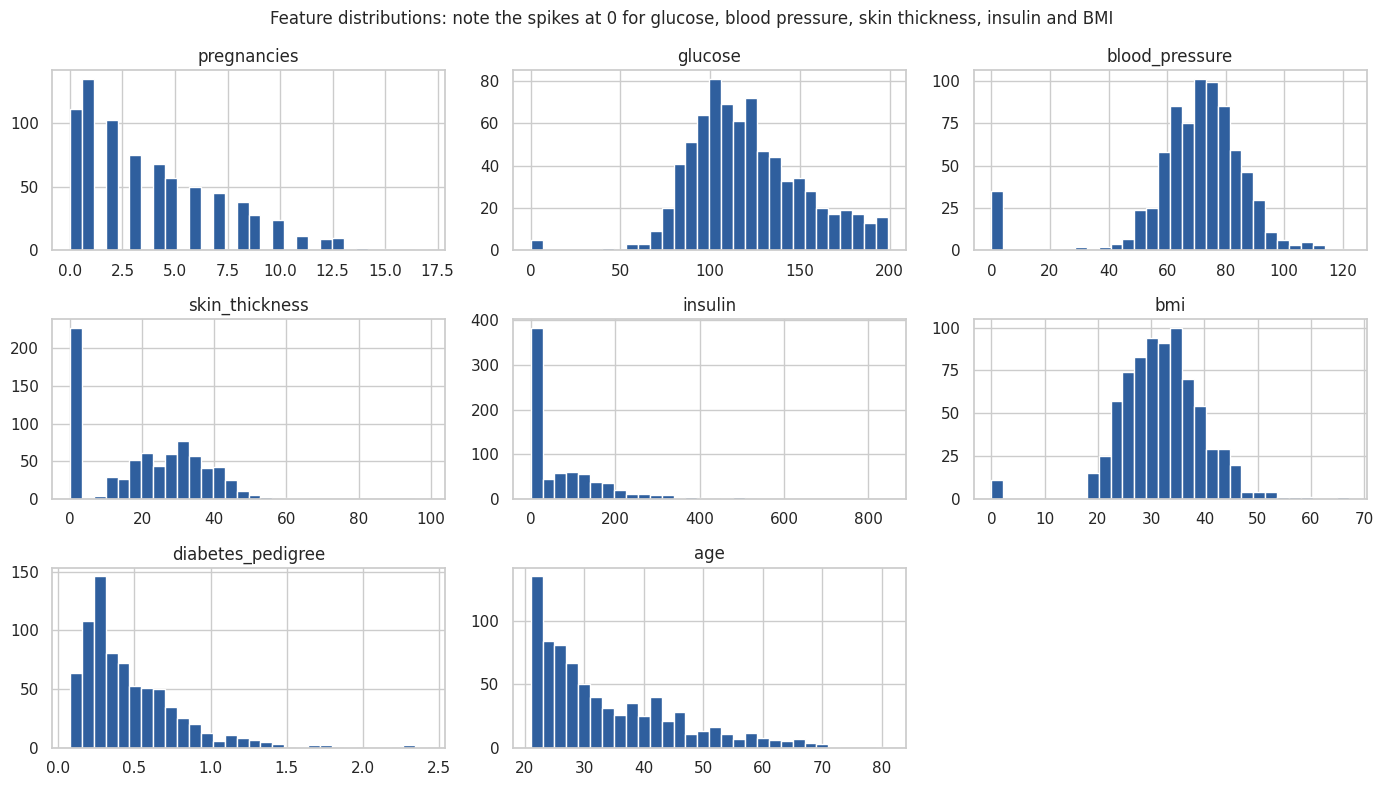

In [3]:
print("=== head() ===")
display(df.head())

print("\n=== info() ===")
df.info()

print("\n=== describe() ===")
display(df.describe().T)

print("\n=== Number of zero values per column ===")
zero_counts = (df.drop(columns="outcome") == 0).sum()
display(zero_counts.to_frame("zero_count"))

print("\n=== Class balance (outcome) ===")
display(df["outcome"].value_counts().rename(index={0: "non-diabetic (0)", 1: "diabetic (1)"})
        .to_frame("patients").assign(percent=lambda t: 100 * t["patients"] / len(df)))

# Histograms make the spike of placeholder zeros easy to see
df.drop(columns="outcome").hist(bins=30, figsize=(14, 8), color="#2F5F9E", edgecolor="white")
plt.suptitle("Feature distributions: note the spikes at 0 for glucose, blood pressure, "
             "skin thickness, insulin and BMI", fontsize=12)
plt.tight_layout()
plt.show()

**Task 3: Quantify and handle implicit missing values with simpleimputer**

,missing_count,missing_percent
insulin,374,48.698
skin_thickness,227,29.557
blood_pressure,35,4.557
bmi,11,1.432
glucose,5,0.651
pregnancies,0,0.000
diabetes_pedigree,0,0.000
age,0,0.000


Rows with at least one missing value: 376 of 768 (49.0%). Deleting them would leave only 392 patients.


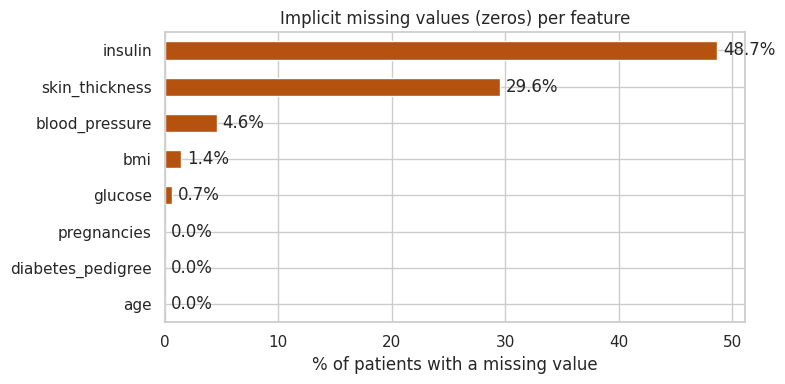


Training set: (614, 8), test set: (154, 8)

Medians learned from the training set:


,median
glucose,117.0
blood_pressure,72.0
skin_thickness,29.0
insulin,125.0
bmi,32.4


Missing values remaining - train: 0 | test: 0


In [4]:
ZERO_AS_MISSING = ["glucose", "blood_pressure", "skin_thickness", "insulin", "bmi"]
OTHER_FEATURES  = ["pregnancies", "diabetes_pedigree", "age"]
FEATURES = ZERO_AS_MISSING + OTHER_FEATURES

# Step 1: make the hidden missing values explicit
df_clean = df.copy()
df_clean[ZERO_AS_MISSING] = df_clean[ZERO_AS_MISSING].replace(0, np.nan)

# Step 2: quantify them
missing = pd.DataFrame({
    "missing_count": df_clean[FEATURES].isna().sum(),
    "missing_percent": 100 * df_clean[FEATURES].isna().mean(),
}).sort_values("missing_percent", ascending=False)
display(missing)

rows_with_missing = df_clean[FEATURES].isna().any(axis=1).sum()
print(f"Rows with at least one missing value: {rows_with_missing} of {len(df_clean)} "
      f"({100 * rows_with_missing / len(df_clean):.1f}%). Deleting them would leave only "
      f"{len(df_clean) - rows_with_missing} patients.")

ax = missing["missing_percent"].plot(kind="barh", figsize=(8, 4), color="#B5520F")
ax.invert_yaxis()
ax.set_xlabel("% of patients with a missing value")
ax.set_title("Implicit missing values (zeros) per feature")
for i, v in enumerate(missing["missing_percent"]):
    ax.text(v + 0.5, i, f"{v:.1f}%", va="center")
plt.tight_layout()
plt.show()

# Step 3: stratified train/test split BEFORE fitting the imputer (prevents leakage)
X = df_clean[FEATURES]
y = df_clean["outcome"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(f"\nTraining set: {X_train.shape}, test set: {X_test.shape}")

# Step 4: median imputation learned from the training data only
imputer = SimpleImputer(strategy="median")
imputer.fit(X_train[ZERO_AS_MISSING])
print("\nMedians learned from the training set:")
display(pd.Series(imputer.statistics_, index=ZERO_AS_MISSING).to_frame("median"))

X_train_imp = X_train.copy()
X_test_imp = X_test.copy()
X_train_imp[ZERO_AS_MISSING] = imputer.transform(X_train[ZERO_AS_MISSING])
X_test_imp[ZERO_AS_MISSING] = imputer.transform(X_test[ZERO_AS_MISSING])
print("Missing values remaining - train:", int(X_train_imp.isna().sum().sum()),
      "| test:", int(X_test_imp.isna().sum().sum()))

**Task 4: Build a ColumnTransformer and Pipeline with appropriate scaling**

In [5]:
from sklearn.base import clone

numeric_with_missing = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

preprocessor = ColumnTransformer([
    ("impute_scale", numeric_with_missing, ZERO_AS_MISSING),
    ("scale", StandardScaler(), OTHER_FEATURES),
])

def make_model(classifier):
    # Return a fresh preprocessing + classifier pipeline
    return Pipeline([("preprocess", clone(preprocessor)), ("clf", classifier)])

# Demonstrate the preprocessor on the RAW (NaN-containing) training data
Xt = preprocessor.fit_transform(X_train)
check = pd.DataFrame(Xt, columns=FEATURES).agg(["mean", "std"]).T
print("Output shape:", Xt.shape, "| missing values after preprocessing:", int(np.isnan(Xt).sum()))
display(check.round(3))

make_model(LogisticRegression())

Output shape: (614, 8) | missing values after preprocessing: 0


,mean,std
glucose,-0.0,1.001
blood_pressure,0.0,1.001
skin_thickness,-0.0,1.001
insulin,-0.0,1.001
bmi,0.0,1.001
pregnancies,-0.0,1.001
diabetes_pedigree,-0.0,1.001
age,-0.0,1.001


Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('impute_scale',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['glucose', 'blood_pressure',
                                                   'skin_thickness', 'insulin',
                                                   'bmi']),
                                                 ('scale', StandardScaler(),
                                                  ['pregnancies',
                                                   'diabetes_pedigree',
                                                   'age'])])),
                ('clf', LogisticRegression())])

**Task 5: Hard and soft Voting Classifiers**

===== Hard Voting: test accuracy = 0.740 =====
              precision    recall  f1-score   support

non-diabetic      0.778     0.840     0.808       100
    diabetic      0.652     0.556     0.600        54

    accuracy                          0.740       154
   macro avg      0.715     0.698     0.704       154
weighted avg      0.734     0.740     0.735       154

===== Soft Voting: test accuracy = 0.734 =====
              precision    recall  f1-score   support

non-diabetic      0.771     0.840     0.804       100
    diabetic      0.644     0.537     0.586        54

    accuracy                          0.734       154
   macro avg      0.708     0.689     0.695       154
weighted avg      0.726     0.734     0.727       154



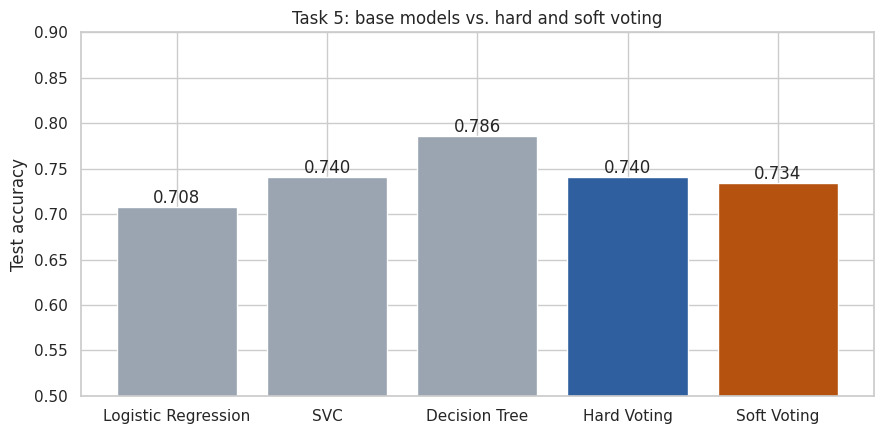

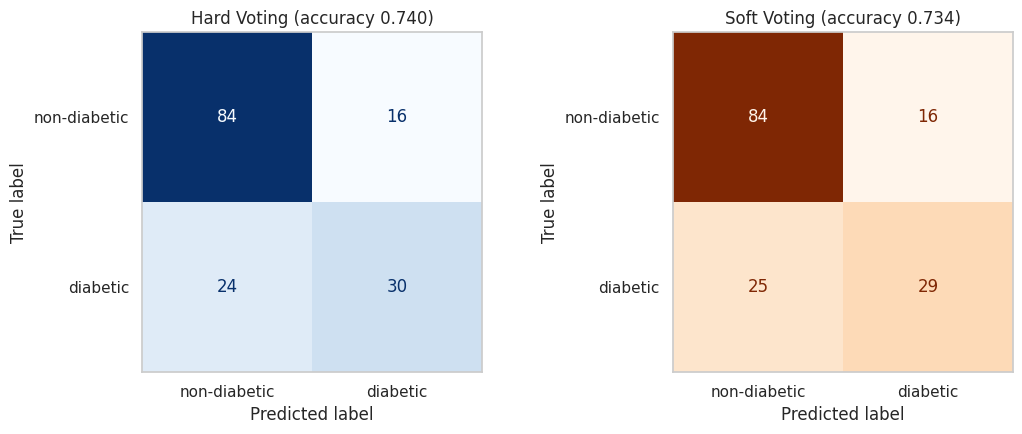

In [6]:
results = {}   # test accuracy of every model, for the final comparison

def evaluate(name, model, show_report=True):
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    acc = accuracy_score(y_test, pred)
    results[name] = acc
    if show_report:
        print(f"===== {name}: test accuracy = {acc:.3f} =====")
        print(classification_report(y_test, pred, target_names=["non-diabetic", "diabetic"], digits=3))
    return pred

log_reg = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
svc     = CalibratedClassifierCV(SVC(kernel="rbf", random_state=RANDOM_STATE),
                                 method="sigmoid", cv=5, ensemble=False)
tree    = DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE)

# Individual base models (for reference)
for name, clf in [("Logistic Regression", log_reg), ("SVC", svc), ("Decision Tree", tree)]:
    evaluate(name, make_model(clf), show_report=False)

estimators = [("lr", log_reg), ("svc", svc), ("dt", tree)]
hard_vote = make_model(VotingClassifier(estimators=estimators, voting="hard"))
soft_vote = make_model(VotingClassifier(estimators=estimators, voting="soft"))

pred_hard = evaluate("Hard Voting", hard_vote)
pred_soft = evaluate("Soft Voting", soft_vote)

# Plot 1: accuracy comparison
names = ["Logistic Regression", "SVC", "Decision Tree", "Hard Voting", "Soft Voting"]
colors = ["#9AA5B1"] * 3 + ["#2F5F9E", "#B5520F"]
fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar(names, [results[n] for n in names], color=colors)
ax.bar_label(bars, fmt="%.3f")
ax.set_ylim(0.5, 0.9)
ax.set_ylabel("Test accuracy")
ax.set_title("Task 5: base models vs. hard and soft voting")
plt.tight_layout()
plt.show()

# Plot 2: confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, pred, title, cmap in [(axes[0], pred_hard, "Hard Voting", "Blues"),
                              (axes[1], pred_soft, "Soft Voting", "Oranges")]:
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["non-diabetic", "diabetic"],
                                            cmap=cmap, ax=ax, colorbar=False)
    ax.set_title(f"{title} (accuracy {accuracy_score(y_test, pred):.3f})")
    ax.grid(False)
plt.tight_layout()
plt.show()

**Task 6: Bagging with bootstrap sampling and out-of-bag (OOB) evaluation**

===== Bagging (500 trees): test accuracy = 0.740 =====
              precision    recall  f1-score   support

non-diabetic      0.773     0.850     0.810       100
    diabetic      0.659     0.537     0.592        54

    accuracy                          0.740       154
   macro avg      0.716     0.694     0.701       154
weighted avg      0.733     0.740     0.733       154

OOB score: 0.757 | test accuracy: 0.740 | difference: +0.017


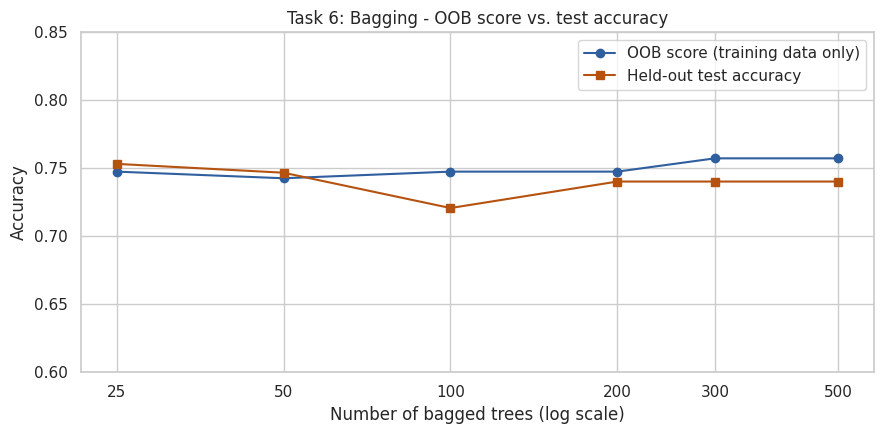

In [7]:
sizes = [25, 50, 100, 200, 300, 500]
oob_scores, test_accs = [], []
for n in sizes:
    bag = make_model(BaggingClassifier(estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
                                       n_estimators=n, bootstrap=True, oob_score=True,
                                       n_jobs=-1, random_state=RANDOM_STATE))
    bag.fit(X_train, y_train)
    oob_scores.append(bag.named_steps["clf"].oob_score_)
    test_accs.append(accuracy_score(y_test, bag.predict(X_test)))

# Final model with 500 trees
bagging = make_model(BaggingClassifier(estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
                                       n_estimators=500, bootstrap=True, oob_score=True,
                                       n_jobs=-1, random_state=RANDOM_STATE))
pred_bag = evaluate("Bagging (500 trees)", bagging)
oob_final = bagging.named_steps["clf"].oob_score_
print(f"OOB score: {oob_final:.3f} | test accuracy: {results['Bagging (500 trees)']:.3f} | "
      f"difference: {oob_final - results['Bagging (500 trees)']:+.3f}")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(sizes, oob_scores, marker="o", color="#2F5F9E", label="OOB score (training data only)")
ax.plot(sizes, test_accs, marker="s", color="#B5520F", label="Held-out test accuracy")
ax.set_xscale("log")
ax.minorticks_off()
ax.set_xticks(sizes)
ax.set_xticklabels(sizes)
ax.set_xlabel("Number of bagged trees (log scale)")
ax.set_ylabel("Accuracy")
ax.set_ylim(0.6, 0.85)
ax.set_title("Task 6: Bagging - OOB score vs. test accuracy")
ax.legend()
plt.tight_layout()
plt.show()

**Task 7: Random Forest with feature subsetting and feature importances**

===== Random Forest: test accuracy = 0.734 =====
              precision    recall  f1-score   support

non-diabetic      0.776     0.830     0.802       100
    diabetic      0.638     0.556     0.594        54

    accuracy                          0.734       154
   macro avg      0.707     0.693     0.698       154
weighted avg      0.728     0.734     0.729       154

Random Forest OOB score: 0.765


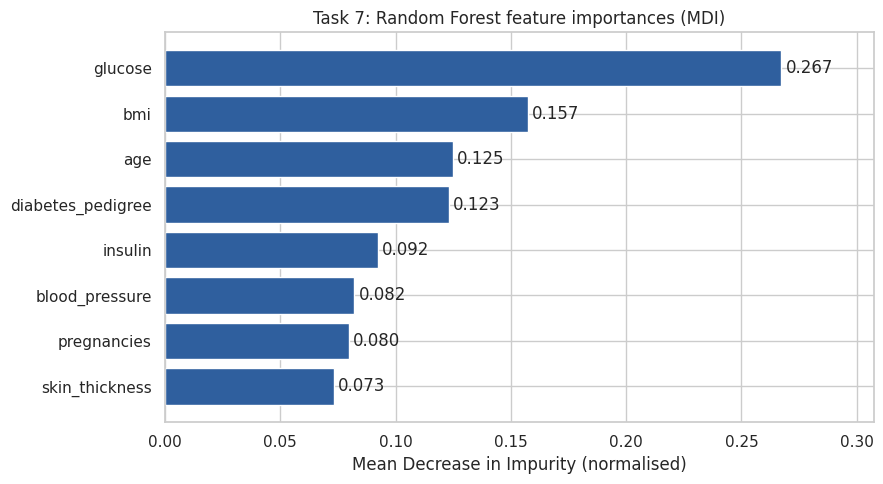

In [8]:
forest = make_model(RandomForestClassifier(n_estimators=500, max_features="sqrt", bootstrap=True,
                                           oob_score=True, n_jobs=-1, random_state=RANDOM_STATE))
pred_rf = evaluate("Random Forest", forest)
print(f"Random Forest OOB score: {forest.named_steps['clf'].oob_score_:.3f}")

importances = (pd.Series(forest.named_steps["clf"].feature_importances_, index=FEATURES)
                 .sort_values())
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(importances.index, importances.values, color="#2F5F9E")
ax.bar_label(bars, fmt="%.3f", padding=3)
ax.set_xlabel("Mean Decrease in Impurity (normalised)")
ax.set_title("Task 7: Random Forest feature importances (MDI)")
ax.set_xlim(0, importances.max() * 1.15)
plt.tight_layout()
plt.show()

**Task 8: AdaBoost with decision stumps**

===== AdaBoost: test accuracy = 0.760 =====
              precision    recall  f1-score   support

non-diabetic      0.789     0.860     0.823       100
    diabetic      0.689     0.574     0.626        54

    accuracy                          0.760       154
   macro avg      0.739     0.717     0.725       154
weighted avg      0.754     0.760     0.754       154

Final training accuracy: 0.809
Final test accuracy:     0.760
Generalisation gap:      0.050
Best test accuracy 0.773 reached after 252 rounds


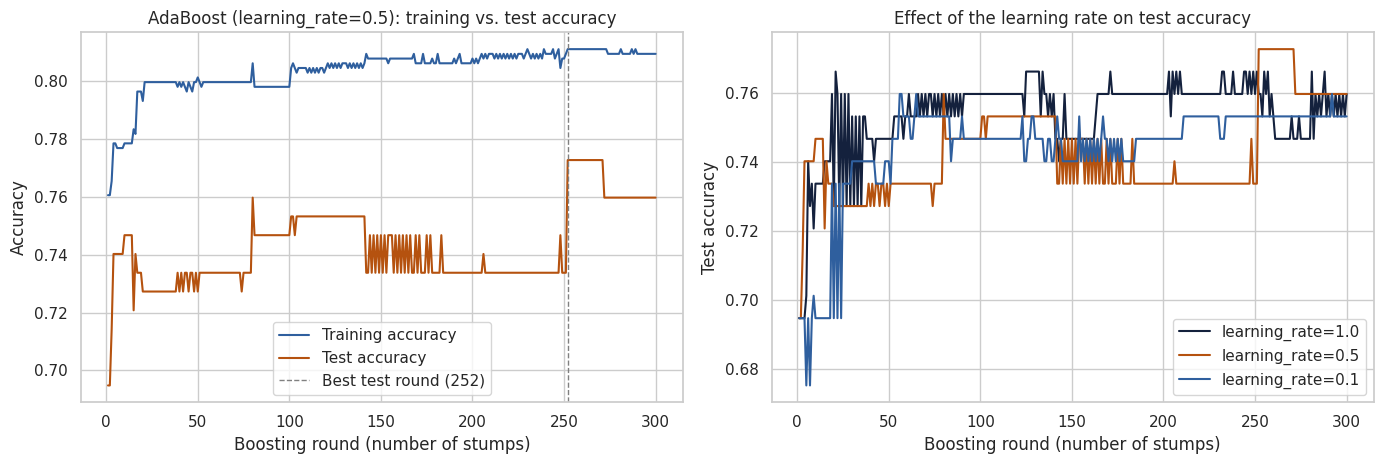

In [9]:
ada = make_model(AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1),
                                    n_estimators=300, learning_rate=0.5,
                                    random_state=RANDOM_STATE))
pred_ada = evaluate("AdaBoost", ada)

prep, booster = ada.named_steps["preprocess"], ada.named_steps["clf"]
Xtr_t, Xte_t = prep.transform(X_train), prep.transform(X_test)
train_curve = list(booster.staged_score(Xtr_t, y_train))
test_curve = list(booster.staged_score(Xte_t, y_test))
rounds = np.arange(1, len(train_curve) + 1)

print(f"Final training accuracy: {train_curve[-1]:.3f}")
print(f"Final test accuracy:     {test_curve[-1]:.3f}")
print(f"Generalisation gap:      {train_curve[-1] - test_curve[-1]:.3f}")
best = int(np.argmax(test_curve))
print(f"Best test accuracy {test_curve[best]:.3f} reached after {best + 1} rounds")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
ax = axes[0]
ax.plot(rounds, train_curve, color="#2F5F9E", label="Training accuracy")
ax.plot(rounds, test_curve, color="#B5520F", label="Test accuracy")
ax.axvline(best + 1, color="gray", linestyle="--", linewidth=1, label=f"Best test round ({best + 1})")
ax.set_xlabel("Boosting round (number of stumps)")
ax.set_ylabel("Accuracy")
ax.set_title("AdaBoost (learning_rate=0.5): training vs. test accuracy")
ax.legend()

ax = axes[1]
for lr, color in [(1.0, "#14213D"), (0.5, "#B5520F"), (0.1, "#2F5F9E")]:
    m = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1), n_estimators=300,
                           learning_rate=lr, random_state=RANDOM_STATE).fit(Xtr_t, y_train)
    ax.plot(rounds, list(m.staged_score(Xte_t, y_test)), color=color, label=f"learning_rate={lr}")
ax.set_xlabel("Boosting round (number of stumps)")
ax.set_ylabel("Test accuracy")
ax.set_title("Effect of the learning rate on test accuracy")
ax.legend()
plt.tight_layout()
plt.show()

**Summary: comparing all models**


,test_accuracy,cv_mean_accuracy,cv_std
model,,,
Random Forest,0.734,0.770,0.027
Hard Voting,0.740,0.766,0.022
Logistic Regression,0.708,0.765,0.031
Bagging (500 trees),0.740,0.764,0.030
AdaBoost,0.760,0.760,0.025
Soft Voting,0.734,0.758,0.026
SVC,0.740,0.756,0.021
Decision Tree,0.786,0.736,0.026


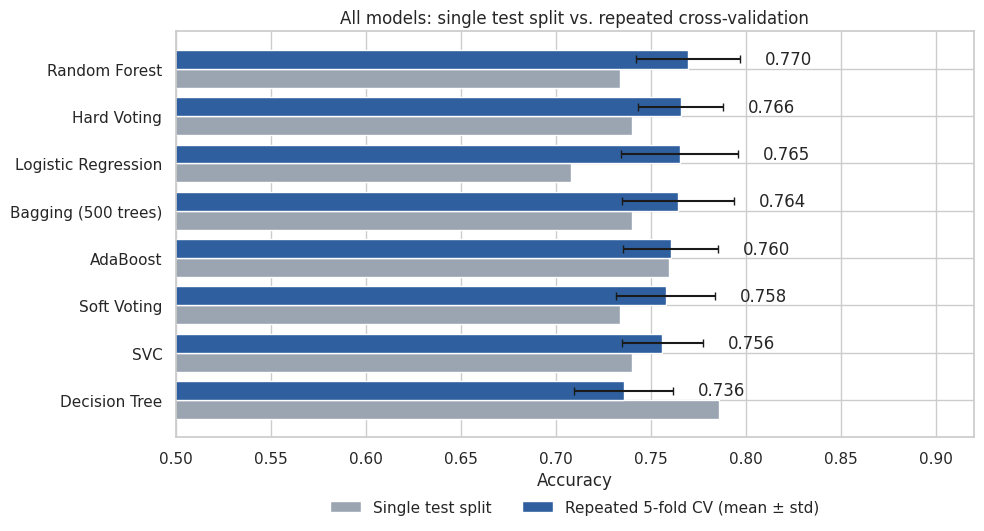

In [10]:
all_models = {
    "Logistic Regression": make_model(log_reg),
    "SVC": make_model(svc),
    "Decision Tree": make_model(tree),
    "Hard Voting": hard_vote,
    "Soft Voting": soft_vote,
    "Bagging (500 trees)": bagging,
    "Random Forest": forest,
    "AdaBoost": ada,
}
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)
rows = []
for name, model in all_models.items():
    scores = cross_val_score(model, X, y, cv=cv, scoring="accuracy", n_jobs=-1)
    rows.append({"model": name, "test_accuracy": results[name],
                 "cv_mean_accuracy": scores.mean(), "cv_std": scores.std()})
summary = pd.DataFrame(rows).set_index("model").sort_values("cv_mean_accuracy", ascending=False)
display(summary.round(3))

plot_df = summary.sort_values("cv_mean_accuracy")
ypos = np.arange(len(plot_df))
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(ypos - 0.2, plot_df["test_accuracy"], height=0.4, color="#9AA5B1", label="Single test split")
bars = ax.barh(ypos + 0.2, plot_df["cv_mean_accuracy"], height=0.4, xerr=plot_df["cv_std"],
               color="#2F5F9E", capsize=3, label="Repeated 5-fold CV (mean ± std)")
ax.bar_label(bars, fmt="%.3f", padding=18)
ax.set_yticks(ypos)
ax.set_yticklabels(plot_df.index)
ax.set_xlim(0.5, 0.92)
ax.set_xlabel("Accuracy")
ax.set_title("All models: single test split vs. repeated cross-validation")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False)
plt.tight_layout()
plt.show()